In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

import numpy as np
import math
import scipy
import matplotlib.pyplot as plt
import seaborn
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

import os
from scipy.optimize import curve_fit
import re
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


In [2]:
# =====================================================================
# GLOBAL FIGURE STYLE — one font family + one font size on every text
# element, and SVG text kept EDITABLE (not outlined) for Illustrator.
# Save any figure as vector with:   fig.savefig("name.svg")
# =====================================================================
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
sns.set_style("white")                 # grid/colour only (does NOT rescale fonts)
sns.set_context("talk", font_scale=1)
FONT_SIZE = 18                              # <- change this one number to rescale ALL text
mpl.rcParams.update({
    "svg.fonttype": "none",                # export text as editable <text>, not paths
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":       FONT_SIZE, "axes.titlesize": FONT_SIZE, "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": 16.5, "ytick.labelsize": 16.5,
    "legend.fontsize": FONT_SIZE, "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE, "axes.titleweight": "normal",
    "mathtext.default": "regular",         # ΔG°$_{37}$ etc. match the body font
    "figure.dpi": 600,
})
sns.set_style(rc={"axes.grid": False})
#sns.set_context("talk", font_scale=1.2)

In [3]:
# === Paper-figure export: one subfolder per panel (figure.svg + data.csv) =====
import os
PAPER_DIR = "Paper_Figures"
def export_panel(name, data=None, save_current_fig=True, note=None):
    """Save the current matplotlib figure and its backing data into Paper_Figures/<name>/."""
    d = os.path.join(PAPER_DIR, name); os.makedirs(d, exist_ok=True)
    if data is not None:
        df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
        df.to_csv(os.path.join(d, "data.csv"), index=False)
    if save_current_fig:
        plt.savefig(os.path.join(d, "figure.svg"), bbox_inches="tight")
    if note is not None:
        open(os.path.join(d, "README.txt"), "w").write(note)
    print("exported ->", d)

def export_panel_high(name, data=None, save_current_fig=True):
    """Write the HIGH-reliability variant (figure_high.svg + data_high.csv) into Paper_Figures/<name>/."""
    d = os.path.join(PAPER_DIR, name); os.makedirs(d, exist_ok=True)
    if data is not None:
        df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
        df.to_csv(os.path.join(d, "data_high.csv"), index=False)
    if save_current_fig:
        plt.savefig(os.path.join(d, "figure_high.svg"), bbox_inches="tight")
    print("exported (high) ->", d)

In [4]:
delta_G37 = {
    "AA/TT": -1.00,
    "AT/TA": -0.88,
    "TA/AT": -0.58,
    "CA/GT": -1.45,
    "GT/CA": -1.44,
    "CT/GA": -1.28,
    "GA/CT": -1.30,
    "CG/GC": -2.17,
    "GC/CG": -2.24,
    "GG/CC": -1.84
}
delta_S = {
    "AA/TT": -22.2,
    "AT/TA": -20.4,
    "TA/AT": -21.3,
    "CA/GT": -22.7,
    "GT/CA": -22.4,
    "CT/GA": -21.0,
    "GA/CT": -22.2,
    "CG/GC": -27.2,
    "GC/CG": -24.4,
    "GG/CC": -19.9
}
delta_H = {
    "AA/TT": -7.9,
    "AT/TA": -7.2,
    "TA/AT": -7.2,
    "CA/GT": -8.5,
    "GT/CA": -8.4,
    "CT/GA": -7.8,
    "GA/CT": -8.2,
    "CG/GC": -10.6,
    "GC/CG": -9.8,
    "GG/CC": -8.0
}

init_H = {"AT": 2.3, "GC": 0.1}
init_S = {"AT": 4.1, "GC": -2.8}
init_G = {"AT": 1.03, "GC": 0.98}

sym_H = 0.0
sym_S = -1.4
sym_G = 0.43


In [5]:
#comp = str.maketrans("ATCG", "TAGC")

comp = str.maketrans("ATCG", "TAGC")

def revcomp(seq):
    return seq.translate(comp)[::-1]


def calc_unified_nn(seq):
    seq = seq.upper()
    rc = revcomp(seq)

    total_H = 0
    total_S = 0
    total_G = 0

    # Sum nearest neighbors
    for i in range(len(seq) - 1):
        top = seq[i:i+2]
        #bottom = rc[len(seq)-i-2:len(seq)-i]  # matching 3'→5' orientation
        bottom = top.translate(comp)
        key = f"{top}/{bottom}"

        if key not in delta_H:
            key_rev = f"{top[::-1]}/{bottom[::-1]}"
            #print(key)
            key = key_rev
            if(key not in delta_H):
                top1 = bottom
                bottom1 = top
                key = f"{top1[::-1]}/{bottom1[::-1]}"
                if(key not in delta_H):
                    raise ValueError(f"Step {key} not found in NN library")

        total_H += delta_H[key]
        total_S += delta_S[key]
        total_G += delta_G37[key]

    # Add initiation terms (two ends)
    for base in (seq[0], seq[-1]):
        pair_type = "AT" if base in "AT" else "GC"
        total_H += init_H[pair_type]
        total_S += init_S[pair_type]
        total_G += init_G[pair_type]

    # Symmetry correction if self-complementary
    if seq == rc:
        total_H += sym_H
        total_S += sym_S
        total_G += sym_G

    return {
        "Delta_H (kcal/mol)": total_H,
        "Delta_S (cal/K/mol)": total_S,
        "Delta_G_37 (kcal/mol)": total_G
    }


In [6]:
def get_Num_NTs(df):
    get_Num_NTs = list()
    for i in range(len(df)):
        str1 = df['Samples'][i]
        if('A' in str1):
            get_Num_NTs.append('A')
        elif('B' in str1):
            get_Num_NTs.append('B')
        elif('6' in str1):
            get_Num_NTs.append(6)
        elif('7' in str1):
            get_Num_NTs.append(7)
        elif('9' in str1):
            get_Num_NTs.append(9)
        elif('5' in str1):
            get_Num_NTs.append(5)
    return get_Num_NTs

In [7]:
def saltCorrection(dG_1M,bp_Len,n_duplex=1):
    Mg_M =0.0113
    Na_M = 0.0
    # Mg2+ -> monovalent-sodium equivalent: [Na+]_eq = 3.3*sqrt([Mg2+])  (sqrt on [Mg] only)
    ionic_term = Na_M + 3.3 * math.sqrt(Mg_M)

    if ionic_term <= 0:
        raise ValueError("Ionic strength must be > 0")

    # salt term scales with phosphate steps: each L-bp duplex has (L-1); a site has n_duplex of them
    n_steps = n_duplex * (bp_Len - 1)
    correction = 0.114 * n_steps * math.log(ionic_term)

    return dG_1M - correction

In [8]:
def add_Pairs(df):
    dH = list()
    dG = list()
    dS = list()
    helices = list()
    for i in range(0, len(df), 2):
        sumdH = df['dH_kcal_mol'][i]+df['dH_kcal_mol'][i+1]
        sumdG = df['dG37_kcal_mol'][i]+df['dG37_kcal_mol'][i+1]
        sumdS = df['dS_cal_K_mol'][i]+df['dS_cal_K_mol'][i+1]
        helix = int(df['Helix'][i])-1
        dH.append(sumdH)
        dG.append(sumdG)
        dS.append(sumdS)
        helices.append(helix)
    parameters=pd.DataFrame({'Helix':helices,'G':dG,'S':dS,'H':dH})
    return parameters

In [9]:
def add_nn_thermo_columns(df: pd.DataFrame) -> pd.DataFrame:
    # calculate thermo for every row
    thermo = df["Sequence"].astype(str).apply(calc_unified_nn)  # returns dict per row

    # expand dicts into columns
    thermo_df = pd.json_normalize(thermo)

    # join back
    out = df.join(thermo_df)

    # optional: shorter column names
    out = out.rename(columns={
        "Delta_H (kcal/mol)": "dH_kcal_mol",
        "Delta_S (cal/K/mol)": "dS_cal_K_mol",
        "Delta_G_37 (kcal/mol)": "dG37_kcal_mol",
    })
    return out

#df = add_nn_thermo_columns(df)

In [10]:
def Get_tm(df, Ct=4.5e-9):
    """
    Predicted Tm for a non-self-complementary bimolecular duplex
        A + B <-> AB :   Tm = dH / (dS + R*ln(C_T/4))
    with C_T = total strand concentration.  Predicted_deltaH is in kcal/mol
    (converted here to cal/mol) and Predicted_deltaS in cal/mol/K, so Tm is in °C.
    """
    R = 1.987204  # gas constant, cal/(mol*K)
    Tm_CList = list()
    for x in range(len(df)):
        dH = df['Predicted_deltaH'][x] * 1000.0   # kcal/mol -> cal/mol
        dS = df['Predicted_deltaS'][x]            # cal/mol/K
        Tm_K = dH / (dS + R * np.log(Ct / 4.0))
        Tm_CList.append(Tm_K - 273.15)
    return Tm_CList


In [11]:
def Keq(temp, theta, C_T=4.5e-9):
    """
    Equilibrium constant for a non-self-complementary BIMOLECULAR duplex
        A + B <-> AB ,  [A]=[B]=C_T/2,  theta = fraction folded:
        K = [AB]/([A][B]) = 2*theta / ((1-theta)**2 * C_T)      (units 1/M)
    C_T = TOTAL single-strand concentration (both strands summed).  The earlier
    version omitted the factor of 2 (bimolecular stoichiometry); that shifted the
    intercept, hence dS, by R*ln(2).  Returns ln(K) and 1/T (K^-1) for interior
    points 0<theta<1.
    """
    temp = np.asarray(temp, float)
    lnKeq = list(); inverseTemp = list()
    for i in range(len(theta)):
        th = theta[i]
        if 0 < th < 1:
            keq = 2.0 * th / ((1.0 - th)**2 * C_T)
            lnKeq.append(math.log(keq))
            inverseTemp.append(1.0 / (temp[i] + 273.15))
    return lnKeq, inverseTemp


In [12]:
def boltzmann(x, A1, A2, x0, dx):
    #return A2 + (A1 - A2) / (1 + np.exp((x - x0)/dx))
    return A1 + (A2 - A1) / (1 + np.exp((x0-x)/dx))

# Standard logistic sigmoid function
def logistic(x, a, b, c, d):
    return a / (1 + np.exp(-c * (x - d))) + b

In [13]:
homeDir = "C:\\Users\\jared\\Downloads\\Tile_TileResults\\"

In [14]:
######## From measured entropy and enthalpy, convert to Delta G ########
def deltaGCalc(entropy, enthalpy, tempCelcius):
    temp=273.15+tempCelcius
    deltaG=enthalpy-temp*entropy/1000
    return deltaG

In [15]:
######## Get Predicted Energy ########
def getEnergy_Seq(df):
    EnergyList = list()
    for a in range(len(df)):
        sample1=df['Samples'][a]
        sample1=sample1.partition('.')[0]
        positions = list(sample1)
        energy = 0
        for i in range(len(positions)):
            arr = positions[i]
            bondLen = arr
            #bondLen = bond_lens[i]
            if(bondLen == '5' or bondLen == 'X'):
                #for x in range(len(arr)):
                energy =energy + nt5_2['G_corrected'][int(i)]
            elif(bondLen == '7'):
                #for x in range(len(arr)):
                energy =energy + nt7_2['G_corrected'][int(i)]
            elif(bondLen == '9'):
                #for x in range(len(arr)):
                energy =energy + nt9_2['G_corrected'][int(i)]
            elif(bondLen == '6'):
                #for x in range(len(arr)):
                energy =energy + nt6_2['G_corrected'][int(i)]
            elif(bondLen == '0'):
                energy = energy + 0
            elif(bondLen == 'A'):
                energy = energy + constant_2['G_corrected'][0]
            elif(bondLen == 'B'):
                energy = energy + constant_2['G_corrected'][1]
            else:
                print('Error')
        EnergyList.append(energy)

    return EnergyList
#df_5nt['Predicted_DeltaG25'] = EnergyList_5nt

In [16]:
######## Get Predicted Energy ########
def getH_Seq(df):
    EnergyList = list()
    for a in range(len(df)):
        sample1=df['Samples'][a]
        sample1=sample1.partition('.')[0]
        positions = list(sample1)
        energy = 0
        for i in range(len(positions)):
            arr = positions[i]
            bondLen = arr
            #bondLen = bond_lens[i]
            if(bondLen == '5' or bondLen == 'X'):
                #for x in range(len(arr)):
                energy =energy + nt5_2['H'][int(i)]
            elif(bondLen == '7'):
                #for x in range(len(arr)):
                energy =energy + nt7_2['H'][int(i)]
            elif(bondLen == '9'):
                #for x in range(len(arr)):
                energy =energy + nt9_2['H'][int(i)]
            elif(bondLen == '6'):
                #for x in range(len(arr)):
                energy =energy + nt6_2['H'][int(i)]
            elif(bondLen == '0'):
                energy = energy + 0
            elif(bondLen == 'A'):
                energy = energy + constant_2['H'][0]
            elif(bondLen == 'B'):
                energy = energy + constant_2['H'][1]
            else:
                print('Error')
        EnergyList.append(energy)

    return EnergyList

In [17]:
######## Get Predicted Energy ########
def getS_Seq(df):
    EnergyList = list()
    for a in range(len(df)):
        sample1=df['Samples'][a]
        sample1=sample1.partition('.')[0]
        positions = list(sample1)
        energy = 0
        for i in range(len(positions)):
            arr = positions[i]
            bondLen = arr
            #bondLen = bond_lens[i]
            if(bondLen == '5' or bondLen == 'X'):
                #for x in range(len(arr)):
                energy =energy + nt5_2['S'][int(i)]
            elif(bondLen == '7'):
                #for x in range(len(arr)):
                energy =energy + nt7_2['S'][int(i)]
            elif(bondLen == '9'):
                #for x in range(len(arr)):
                energy =energy + nt9_2['S'][int(i)]
            elif(bondLen == '0'):
                energy = energy + 0
            elif(bondLen == '6'):
                #for x in range(len(arr)):
                energy =energy + nt6_2['S'][int(i)]
            elif(bondLen == 'A'):
                energy = energy + constant_2['S'][0]
            elif(bondLen == 'B'):
                energy = energy + constant_2['S'][1]
            else:
                print('Error')
        EnergyList.append(energy)

    return EnergyList

In [18]:
def getNum_Bonds_Positions(edgeCodeList):
    df=pd.DataFrame({'Samples':edgeCodeList})
    df['Samples'] = df['Samples'].str.split('.', n=1).str[0]
    positions=df['Samples'].apply(lambda x: [i for i, char in enumerate(x) if char != '0'])
    numBonds = list()
    for i in range(len(positions)):
        #positions[i].append(6)
        numBonds.append(len(positions[i]))

    return numBonds, positions

In [19]:
def getBonds_Positions_Microstates(edgeCodeList):
    df=pd.DataFrame({'Samples':edgeCodeList})
    df['Samples'] = df['Samples'].str.split('.', n=1).str[0]
    positions=df['Samples'].apply(lambda x: [i for i, char in enumerate(x) if char != '0'])
    numBonds = list()
    for i in range(len(positions)):
        numBonds.append(len(positions[i]))
        
    return numBonds, positions

In [20]:
def getDistances(positions):
    distanceList = list()
    for i in range(len(positions)):
        arr = np.array(positions[i])
        distances = pdist(arr.reshape(-1, 1))
        avgDist =np.mean(distances)
        distanceList.append(avgDist)
    return distanceList

In [21]:
#A
#print(calc_unified_nn('GACGGCC'))
#print(calc_unified_nn('CGGCAGC'))

#B
#GCGGCTG
#GCGCGGA

Sequence = ['GACGGCC','CGGCAGC','GCGGCTG','GCGCGGA']
constant=pd.DataFrame({'Helix':['0','0','1','1'],'Sequence':Sequence})

In [22]:
constant_1 = add_nn_thermo_columns(constant)
constant_2 = add_Pairs(constant_1)
constant_2["G_corrected"] = constant_2.apply(lambda row: saltCorrection(
        dG_1M=row['G'],
        bp_Len=7, n_duplex=2),axis = 1)
constant_2['Helix'] = ['A','B']

In [23]:
constant_2

,Helix,G,S,H,G_corrected
0,A,-18.16,-288.3,-107.6,-16.726946
1,B,-19.20,-288.9,-108.8,-17.766946


In [24]:
nt7 = pd.read_csv("nt7.csv", index_col=0)

In [25]:
nt6 = pd.read_csv("nt6.csv", index_col=0)

In [26]:
nt5 = pd.read_csv("nt5.csv", index_col=0)

In [27]:
nt9 = pd.read_csv("nt9.csv", index_col=0)

In [28]:
nt9_stack = pd.read_csv("nt9_stack.csv", index_col=0)

In [29]:
nt9_stack

,Stacking,G
0,-9.47,NaN
1,-7.89,NaN
2,-9.29,NaN
3,-7.41,NaN
4,-7.96,NaN
5,-9.27,NaN
6,-6.79,NaN
7,-10.11,NaN
8,-8.52,NaN
9,-8.26,NaN


In [30]:
nt9

,Helix,Sequence
0,1.0,AAGGGTTTT
1,NaN,TTTGTGGAA
2,2.0,AAAACAATT
3,NaN,TTGATGGAA
4,3.0,AACACCATT
5,NaN,TTTAACTAA
6,4.0,AACACGGTT
7,NaN,TTTCTATAA
8,5.0,AATTCATTT
9,NaN,TTGCTTGAA


In [31]:
nt9_1 = add_nn_thermo_columns(nt9)
nt9_2 = add_Pairs(nt9_1)
nt9_2['G'] = nt9_2['G']+nt9_stack['Stacking']
nt9_2["G_corrected"] = nt9_2.apply(lambda row: saltCorrection(
        dG_1M=row['G'],
        bp_Len=9, n_duplex=2),axis = 1)

nt7_1 = add_nn_thermo_columns(nt7)
nt7_2 = add_Pairs(nt7_1)
nt7_2["G_corrected"] = nt7_2.apply(lambda row: saltCorrection(
        dG_1M=row['G'],
        bp_Len=7, n_duplex=2),axis = 1)

nt5_1 = add_nn_thermo_columns(nt5)
nt5_2 = add_Pairs(nt5_1)
nt5_2["G_corrected"] = nt5_2.apply(lambda row: saltCorrection(
        dG_1M=row['G'],
        bp_Len=5, n_duplex=2),axis = 1)

nt6_1 = add_nn_thermo_columns(nt6)
nt6_2 = add_Pairs(nt6_1)
nt6_2["G_corrected"] = nt6_2.apply(lambda row: saltCorrection(
        dG_1M=row['G'],
        bp_Len=6, n_duplex=2),axis = 1)

In [32]:
######## Get Predicted Energy ########
def make_Energy_Array(df):
    A = np.zeros((len(df), 11))
    #EnergyList = list()
    for a in range(len(df)):
        sample1=df['Samples'][a]
        sample1=sample1.partition('.')[0]
        positions = list(sample1)
        energy = 0
        for i in range(len(positions)):
            arr = positions[i]
            bondLen = arr
            #bondLen = bond_lens[i]
            if(bondLen == '5' or bondLen == 'X'):
                #for x in range(len(arr)):
                A[a,i] += nt5_2['G_corrected'][int(i)]

            elif(bondLen == '7'):
                #for x in range(len(arr)):
                A[a,i] += nt7_2['G_corrected'][int(i)]
            elif(bondLen == '9'):
                #for x in range(len(arr)):
                A[a,i] += nt9_2['G_corrected'][int(i)]
            elif(bondLen == '6'):
                #for x in range(len(arr)):
                A[a,i] += nt6_2['G_corrected'][int(i)]
            elif(bondLen == '0'):
                A[a,i] += 0
            elif(bondLen == 'A'):
                A[a,i] += constant_2['G_corrected'][0]
            elif(bondLen == 'B'):
                A[a,i] += constant_2['G_corrected'][1]
            else:
                print('Error')
    return A
#df_5nt['Predicted_DeltaG25'] = EnergyList_5nt

In [33]:
data_key = {
    "Thermo10_28_2025_Formatted.csv":"Tile_TileResultsKey - 10_28_2025.csv",
    "DNAExtensionThermo10_29_Formatted.csv":"Tile_TileResultsKey - 10_29_2025.csv",
    "DNAExtensionThermo10_30_Formatted.csv":"Tile_TileResultsKey - 10_30_2025.csv",
    "DNAExtensionThermo11_3_Formatted.csv":"Tile_TileResultsKey - 11_3_2025.csv",
    "DNAExtensionThermo11_6_Formatted.csv":"Tile_TileResultsKey - 11_6_2025.csv",
    "DNAExtensionThermo11_14.csv":"Tile_TileResultsKey - 11_14_2025.csv",
    "DNAExtensionThermo11_15.csv":"Tile_TileResultsKey - 11_15_2025.csv",
    "DNAExtensionThermo11_16.txt":"Tile_TileResultsKey - 11_16_2025.csv",
    "DNAExtensionThermo11_17.txt":"Tile_TileResultsKey - 11_17_2025.csv"
}

In [34]:
def fitNormalized(data, YVar):
    """Same NEW fitted-baseline van't Hoff fit as fit_Not_Normalized."""
    R = 1.987204; C_T = 4.5e-9
    T  = np.asarray(data['T° 569'], float)
    s0 = np.asarray(data.iloc[:, YVar], float)
    ok = np.isfinite(T) & np.isfinite(s0); T, s0 = T[ok], s0[ok]
    if len(T) < 12:
        raise ValueError("too few points")
    # robust two-state fit THROUGH the read noise -> baselines, midpoint, width
    p0 = [np.percentile(s0, 5), np.percentile(s0, 95), np.median(T), 3.0]
    (A1, A2, x0, dx), _ = curve_fit(boltzmann, T, s0, p0=p0, maxfev=20000)
    if not np.isfinite(dx) or dx <= 0 or not (T.min() - 5 < x0 < T.max() + 5):
        raise ValueError("bad sigmoid fit")
    Tm = x0
    # fraction folded from the FITTED baselines (+ light rolling median for read noise)
    s = pd.Series(s0).rolling(7, center=True, min_periods=1).median().values
    theta = (A2 - s) / (A2 - A1) if A2 > A1 else (s - A2) / (A1 - A2)
    theta = np.clip(theta, 1e-4, 1 - 1e-4)
    Tk = T + 273.15
    # The sigmoid midpoint (Tm) above is already valid. If the van't Hoff step
    # fails -- too few points in the linear region, or an unphysical positive
    # dH/dS -- KEEP the Tm and return dH=dS=NaN rather than discarding the curve.
    # Only a failed *sigmoid* fit (handled above) removes a Tm.
    region = (theta > 0.15) & (theta < 0.85)               # linear region of van't Hoff plot
    if region.sum() < 8:
        return [Tm, dx], None, np.nan, np.nan, (0.0, 1.0, Tm, dx)
    x = 1.0 / Tk[region]
    y = np.log(2.0 * theta[region] / ((1.0 - theta[region])**2 * C_T))   # bimolecular K
    o = np.argsort(x); x, y = x[o], y[o]
    m, b = np.polyfit(x, y, 1)
    enthalpy = -m * R / 1000.0        # kcal/mol
    entropy  =  b * R                 # cal/(mol*K)
    if not np.isfinite(enthalpy) or enthalpy >= 0 or entropy >= 0:
        return [Tm, dx], None, np.nan, np.nan, (0.0, 1.0, Tm, dx)   # keep Tm, drop dH/dS
    # normalized boltzmann params (A1=0, A2=1) keep the downstream melting-curve plot valid
    return [Tm, dx], None, entropy, enthalpy, (0.0, 1.0, Tm, dx)


In [35]:
def fit_Not_Normalized(data, YVar):
    """Droop-corrected two-state fit with a Tm-reliability rule.
    1) flat Boltzmann fit -> transition (x0, dx).
    2) droop trim: cut at the post-transition plateau peak + 3C, REFIT -> droop-corrected Tm=x0
       and its covariance SE.
    3) reliability: midpoint bracketed by data, transition sampled on BOTH sides, SE(Tm)<=1.5C.
       confidence: 'high' if both plateaus seen (>=3 pts each) AND SE<=1.0C, else 'standard'.
    4) van't Hoff dH/dS on the trimmed data over theta in [0.15,0.85] (NaN if too few pts / unphysical).
    Returns [Tm,dx], extras(dict), entropy, enthalpy, (0.0,1.0,Tm,dx). Raises only on an unfittable sigmoid."""
    R = 1.987204; C_T = 4.5e-9
    T  = np.asarray(data['T° 569'], float)
    s0 = np.asarray(data.iloc[:, YVar], float)
    ok = np.isfinite(T) & np.isfinite(s0); T, s0 = T[ok], s0[ok]
    if len(T) < 14:
        raise ValueError("too few points")
    o = np.argsort(T); T, s0 = T[o], s0[o]
    p0 = [np.percentile(s0, 5), np.percentile(s0, 95), np.median(T), 3.0]
    (A1, A2, x0, dx), _ = curve_fit(boltzmann, T, s0, p0=p0, maxfev=20000)
    if not np.isfinite(dx) or dx <= 0 or A2 <= A1 or not (T.min() - 5 < x0 < T.max() + 5):
        raise ValueError("bad sigmoid fit")
    # ---- droop trim: plateau peak (onset) + 3C, then REFIT with covariance ----
    sm = pd.Series(s0).rolling(7, center=True, min_periods=1).median().values
    post = T > (x0 + 1.5 * dx); onset = T.max()
    if post.sum() >= 3:
        idx = np.where(post)[0]; onset = T[idx[np.argmax(sm[idx])]]
    cut = min(onset + 3.0, T.max()); keep = T <= cut
    if keep.sum() < 12: keep = np.ones_like(T, bool)
    Tf, sf = T[keep], s0[keep]
    try:
        (A1, A2, x0, dx), cov = curve_fit(boltzmann, Tf, sf, p0=p0, maxfev=20000)
        if not np.isfinite(dx) or dx <= 0 or A2 <= A1 or not (Tf.min() - 5 < x0 < Tf.max() + 5):
            raise RuntimeError
        se = float(np.sqrt(np.diag(cov))[2]) if np.all(np.isfinite(cov)) else np.inf
    except Exception:
        Tf, sf = T, s0
        (A1, A2, x0, dx), cov = curve_fit(boltzmann, Tf, sf, p0=p0, maxfev=20000)
        se = float(np.sqrt(np.diag(cov))[2]) if np.all(np.isfinite(cov)) else np.inf
    Tm = x0
    # ---- theta from fitted baselines on trimmed data ----
    s = pd.Series(sf).rolling(7, center=True, min_periods=1).median().values
    theta = (A2 - s) / (A2 - A1) if A2 > A1 else (s - A2) / (A1 - A2)
    theta = np.clip(theta, 1e-4, 1 - 1e-4)
    up = int(np.sum(theta < 0.15)); lo = int(np.sum(theta > 0.85))
    plateau_ok = (up >= 3) and (lo >= 3)
    bracketed  = bool(Tf.min() < x0 < Tf.max())
    bothsides  = (np.sum((theta < 0.5) & (theta > 0.15)) >= 2) and (np.sum((theta > 0.5) & (theta < 0.85)) >= 2)
    reliable   = bool(bracketed and bothsides)   # option 3: per-rep keep = bracketed + both-sides; SE is applied per-CONSTRUCT (median) in df_Tm
    confidence = 'high' if (plateau_ok and np.isfinite(se) and se <= 1.0) else 'standard'
    extras = {'se': se, 'plateau_ok': plateau_ok, 'bracketed': bracketed,
              'bothsides': bool(bothsides), 'reliable': reliable, 'confidence': confidence}
    # ---- van't Hoff dH/dS on trimmed data ----
    Tk = Tf + 273.15
    region = (theta > 0.15) & (theta < 0.85)
    entropy = enthalpy = np.nan
    if region.sum() >= 8:
        x = 1.0 / Tk[region]
        y = np.log(2.0 * theta[region] / ((1.0 - theta[region])**2 * C_T))
        oo = np.argsort(x); x, y = x[oo], y[oo]
        m, b = np.polyfit(x, y, 1)
        enth = -m * R / 1000.0; ent = b * R
        if np.isfinite(enth) and enth < 0 and ent < 0:
            entropy, enthalpy = ent, enth
    return [Tm, dx], extras, entropy, enthalpy, (0.0, 1.0, Tm, dx)

In [36]:
def load_melting2():
    homeDir = "Melting_Results/"
    files=os.listdir(homeDir)
    for file in files:
        if('.txt' in file):
           meltData =pd.read_csv(homeDir + file, sep = '\t', encoding='unicode_escape')
        elif('.csv' in file):
            meltData = pd.read_csv(homeDir + file, encoding='unicode_escape')
        else:
            continue
        samples = meltData.columns[2:,]
        meltData.columns.values[1] = 'T° 569'
        meltData = meltData.drop(meltData.columns[0], axis=1)
    return meltData

In [37]:
def loadAll_Data2(homeDir):
    files = os.listdir(homeDir); a = 0; table1 = None
    for file in files:
        if '.txt' in file:
            meltData = pd.read_csv(homeDir + file, sep='\t', encoding='unicode_escape')
        elif '.csv' in file:
            meltData = pd.read_csv(homeDir + file, encoding='unicode_escape')
        else:
            continue
        meltData.columns.values[1] = 'T° 569'
        meltData = meltData.drop(meltData.columns[0], axis=1)
        data615 = meltData
        melts=[]; samples=[]; delta=[]; dx=[]; entropyList=[]; enthalpyList=[]
        seL=[]; platL=[]; relL=[]; confL=[]
        for val in range(len(data615.columns)):
            name = data615.columns[val]
            if name in ('T° 569', 'Buffer', 'F Only'):
                continue
            try:
                res1, extras, entropy, enthalpy, boltzmannParam = fit_Not_Normalized(data615, val)
                melts.append(res1[0]); delta.append(res1[1]); dx.append(boltzmannParam[3])
                entropyList.append(entropy); enthalpyList.append(enthalpy); samples.append(name)
                seL.append(extras['se']); platL.append(extras['plateau_ok'])
                relL.append(extras['reliable']); confL.append(extras['confidence'])
            except Exception:
                melts.append('None'); delta.append('None'); dx.append('None')
                entropyList.append('None'); enthalpyList.append('None'); samples.append(name)
                seL.append('None'); platL.append(False); relL.append(False); confL.append('None')
        experiment = np.full(len(melts), file)
        t = pd.DataFrame({'Tm':melts,'Samples':samples,'Steepness':delta,'Entropy':entropyList,
                          'Enthalpy':enthalpyList,'Experiment':experiment,'A1':0.0,'A2':1.0,
                          'x0':melts,'dx':dx,'Tm_SE':seL,'Plateau_OK':platL,
                          'Reliable':relL,'Confidence':confL})
        table1 = t if a == 0 else pd.concat([table1, t], ignore_index=True)
        a += 1
    return table1

In [38]:
def filterData(df):
    df["Code"] = df["Samples"].astype(str).str.partition(".")[0]

    g = df.groupby("Code")["Tm"]
    counts = g.size()
    
    tol = 0.05
    spread = (g.max() - g.min()) / g.median()
    ok_base = (counts.eq(3)) & (spread.le(tol))
    
    df_ok = df[df["Code"].isin(ok_base[ok_base].index)]
    return df_ok

In [39]:
def filterData_std(df, std_threshold=2.5):
    """Replicate-reproducibility QC on Tm: keep interfaces (Code) that have
    exactly 3 replicates whose Tm standard deviation is <= std_threshold (°C)."""
    df = df.copy()
    df["Code"] = df["Samples"].astype(str).str.partition(".")[0]
    g = df.dropna(subset=["Tm"]).groupby("Code")["Tm"]
    summary = g.agg(["mean", "std", "count"])
    passing = summary[
        (summary["count"] == 3) &
        (summary["std"] <= std_threshold)
    ]
    df_good = df[df["Code"].isin(passing.index)]
    return df_good

In [40]:
def filterData_std_H(df):
    df["Code"] = df["code"].astype(str).str.partition(".")[0]

    g = df.groupby("Code")["dH"]
    
    # Compute summary stats
    summary = g.agg(["mean", "std", "count"])
    
    # Define your std threshold
    std_threshold = 10.0  # adjust as needed
    
    # Apply both criteria
    passing = summary[
        (summary["count"] == 3) & 
        (summary["std"] <= std_threshold)
    ]
    
    # Get filtered dataframe
    df_good = df[df["Code"].isin(passing.index)]
    return df_good

In [41]:
def format_Melting(meltdf, key_df):
    homeDir = "C:\\Users\\jared\\Downloads\\Tile_TileResults\\"
    if(meltdf == "DNAExtensionThermo11_6_Formatted.csv" or meltdf == 'Thermo10_28_2025_Formatted.csv'):
        pandasDF_melt = pd.read_csv(homeDir+ meltdf)
        pandas_key =  pd.read_csv(homeDir+ key_df)
        samples  = pandas_key['Unnamed: 1']
    
    elif(meltdf == "DNAExtensionThermo11_15.csv"):
        pandasDF_melt = pd.read_csv(homeDir+ meltdf, encoding='unicode_escape')
        #samples  = pandas_key['Unnamed: 1']
        samples  = pandasDF_melt.columns[2:]

    elif(meltdf == "DNAExtensionThermo11_14.csv"):
        pandasDF_melt = pd.read_csv(homeDir+ meltdf)
        #samples  = pandas_key['Unnamed: 1']
        samples  = pandasDF_melt.columns[2:]
    
    elif(meltdf == "DNAExtensionThermo11_16.txt" or meltdf == "DNAExtensionThermo11_17.txt"):
        pandasDF_melt = pd.read_csv(homeDir+ meltdf, encoding='unicode_escape', sep ='\t')
        #samples  = pandas_key['Unnamed: 1']
        samples  = pandasDF_melt.columns[2:]
    
    else:
        pandasDF_melt = pd.read_csv(homeDir+ meltdf, encoding='unicode_escape')
        pandas_key =  pd.read_csv(homeDir+ key_df)
        samples  = pandas_key['Unnamed: 1']
    
    pandasDF_Samples = pandasDF_melt.iloc[:,2:]     
    temp = pandasDF_melt['T° 569']
    pandasDF_Samples.columns = samples
    pandasDF_Samples['T° 569'] = temp
    #pandasDF_Samples = pandasDF_Samples.dropna()
    return pandasDF_Samples

In [42]:
def load_allData(data_key):
    a = 0

    dataReformat = ["DNAExtensionThermo11_14.csv",
    "DNAExtensionThermo11_15.csv",
    "DNAExtensionThermo11_16.txt",
    "DNAExtensionThermo11_17.txt"]
    
    for key in data_key.keys():

        if key in dataReformat:
            meltData=format_Melting(key,data_key[key])
            nt_Count = np.full(len(meltData.columns)-1, 7)
        
        else:
            meltData=format_Melting(key,data_key[key])
            
            if(key == "Thermo10_28_2025_Formatted.csv"):
                nt_Count = np.full(len(meltData.columns)-1, 7)
            
            elif(key == "DNAExtensionThermo10_29_Formatted.csv"):
                meltData.drop('00000X01011', axis=1, inplace = True)
                meltData.drop('00001X00101', axis=1, inplace = True)
                meltData.drop('00001X00110', axis=1, inplace = True)
                meltData.drop('00001X11000', axis=1, inplace = True)
                meltData.drop('00010X00011', axis=1, inplace = True)
    
                nt_Count = np.full(len(meltData.columns)-1, 7)
    
            elif(key == "DNAExtensionThermo10_30_Formatted.csv"):
                nt_Count = np.full(len(meltData.columns)-1, 9)
    
            elif(key == "DNAExtensionThermo11_3_Formatted.csv"):
                nt_Count = np.full(len(meltData.columns)-1, 5)
            
            elif(key == "DNAExtensionThermo11_6_Formatted.csv"):
                legend=data_key[key]
                pandas_key=pd.read_csv(homeDir+legend)
                nt_Count=pandas_key['Unnamed: 3'].apply(lambda x: int(x[0]) if x else None)


        data615 = meltData
        #print(data615)
        melts  = list()
        samples=list()
        delta=list()
        entropyList = list()
        enthalpyList = list()
        for val in range(len(data615.columns)):
            name = data615.columns[val]
            if(name != 'T° 569' and name != 'Buffer' and name != 'F Only'):
                try:
                    res1,day, entropy, enthalpy=fitNormalized(data615,val)
                    entropyList.append(entropy/4184)
                    enthalpyList.append(enthalpy/4184)
                    melts.append(res1[0])
                    delta.append(res1[1])
                    #melts.append(fitAndPlot(data615,name)[0])
                    samples.append(name)
                except:
                    melts.append('None')
                    delta.append('None')
                    entropyList.append('None')
                    enthalpyList.append('None')
                    samples.append(name)
        experiment = np.full(len(melts), key)
        if(a==0):
            table1=pd.DataFrame({'Tm':melts, 'Samples':samples, 'Steepness':delta,'Entropy':entropyList,
                                 'Enthalpy':enthalpyList,'NucleotideBonds':nt_Count,'Experiment':experiment})
        if(a != 0):
            table2=pd.DataFrame({'Tm':melts, 'Samples':samples, 'Steepness':delta,'Entropy':entropyList,
                     'Enthalpy':enthalpyList,'NucleotideBonds':nt_Count,'Experiment':experiment})
            table1 = pd.concat([table1,table2], ignore_index=True)
        a = a+1
    return table1

In [43]:
fil=os.listdir("Melting_Results/")
meltData =pd.read_csv("Melting_Results/" + fil[0], sep = ',', encoding='unicode_escape')

In [44]:
res_Table = loadAll_Data2("Melting_Results/")
#res_Table = res_Table[res_Table['Tm'] != 'None']

/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_11542/3150382055.py:3: RuntimeWarning: overflow encountered in exp
  return A1 + (A2 - A1) / (1 + np.exp((x0-x)/dx))
/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_11542/3150382055.py:3: RuntimeWarning: overflow encountered in exp
  return A1 + (A2 - A1) / (1 + np.exp((x0-x)/dx))
/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_11542/2873712822.py:18: OptimizeWarning: Covariance of the parameters could not be estimated
  (A1, A2, x0, dx), _ = curve_fit(boltzmann, T, s0, p0=p0, maxfev=20000)
/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_11542/3150382055.py:3: RuntimeWarning: overflow encountered in exp
  return A1 + (A2 - A1) / (1 + np.exp((x0-x)/dx))
/var/folders/j7/b00pvk852pndlrr3y6zcy8380000gn/T/ipykernel_11542/2873712822.py:18: OptimizeWarning: Covariance of the parameters could not be estimated
  (A1, A2, x0, dx), _ = curve_fit(boltzmann, T, s0, p0=p0, maxfev=20000)
/var/folders/j7/b00pvk

In [ ]:
#dfFilter = pd.read_csv('Filtered_DF_std.csv')
#dfFilter.drop(['Unnamed: 0'], axis =1, inplace = True)

In [45]:
res_Table = res_Table[res_Table['Tm'] != 'None'].copy()
# loadAll_Data2 mixes float fits with 'None' -> object dtype; make numeric columns numeric
for _c in ['Tm', 'Steepness', 'Entropy', 'Enthalpy', 'A1', 'A2', 'x0', 'dx', 'Yield', 'Tm_SE']:
    if _c in res_Table.columns:
        res_Table[_c] = pd.to_numeric(res_Table[_c], errors='coerce')


In [46]:
# === AUTHORITATIVE Tm TABLE ============================================
# Droop-corrected Tm (onset+3C refit), reliability rule applied per curve in the
# fit (midpoint bracketed, transition both sides, covariance SE(Tm)<=1.5C).
# Reproducible: >=3 reliable reps with Tm std <= 2.5C. Confidence tier per
# construct: 'high' if ALL reps are plateau-complete AND SE<=1.0C, else 'standard'.
# Carries Tm_SE (median), plateau_confident, n_reps. Independent of dH/dS.
_r = res_Table.copy()
_r['Tm']    = pd.to_numeric(_r['Tm'], errors='coerce')
_r['Tm_SE'] = pd.to_numeric(_r['Tm_SE'], errors='coerce')
_r['Reliable']   = _r['Reliable'].apply(lambda v: v is True or str(v) == 'True')
_r['Plateau_OK'] = _r['Plateau_OK'].apply(lambda v: v is True or str(v) == 'True')
_r = _r[_r['Reliable'] & _r['Tm'].notna()].reset_index(drop=True)
_r = _r[~_r['Samples'].astype(str).str.contains('9')].reset_index(drop=True)  # ignore 9nt bonds (stacking handled separately)
# geometry / sequence annotations
_r['NucleotideBonds']               = get_Num_NTs(_r)
_r['Num_Bonds'], _r['Positions']    = getNum_Bonds_Positions(_r['Samples'])
_r['Distances']                     = getDistances(_r['Positions'])
_r['Predicted_deltaS']              = getS_Seq(_r)
_r['Predicted_deltaH']              = getH_Seq(_r)
_r['Predicted_deltaG']              = getEnergy_Seq(_r)
_r['Predicted_tm']                  = Get_tm(_r)
_r['Code']                          = _r['Samples'].astype(str).str.partition('.')[0]
def _mg(pos):
    a = np.sort(np.asarray(pos, float)); g = np.diff(a)
    return g.mean() if len(g) > 0 else np.nan
_r['MeanGap']    = _r['Positions'].map(_mg)
_r['MeanGap_nm'] = _r['MeanGap'] * (60/10)
_r['Distances_nm'] = _r['Distances'] * (60/10)
# reproducibility: >=3 reliable reps, Tm std <= 2.5C
# option 3: construct kept if >=3 reliable reps, Tm std <= 2.5C, and MEDIAN rep SE <= 1.5C
_ag = _r.groupby('Code').agg(_std=('Tm','std'), _cnt=('Tm','count'), _medse=('Tm_SE','median'))
_good = _ag[(_ag['_cnt'] >= 3) & (_ag['_std'] <= 2.5) & (_ag['_medse'] <= 1.5)].index
df_Tm = _r[_r['Code'].isin(_good)].reset_index(drop=True)
# confidence tier + n_reps
_conf = df_Tm.groupby('Code')['Plateau_OK'].all()
df_Tm['plateau_confident'] = df_Tm['Code'].map(lambda c: 'high' if bool(_conf.get(c, False)) else 'standard')
df_Tm['n_reps'] = df_Tm['Code'].map(df_Tm['Code'].value_counts())
# per-construct median table (for Tm figures)
df_Tm_median = (df_Tm.groupby('Code', as_index=False)
    .agg({'Experiment':'first','NucleotideBonds':'first','Num_Bonds':'first','Positions':'first',
          'Distances':'first','Predicted_deltaG':'first','Predicted_deltaS':'first',
          'Predicted_deltaH':'first','Predicted_tm':'first','MeanGap':'first','MeanGap_nm':'first',
          'Distances_nm':'first','plateau_confident':'first','n_reps':'first',
          'Tm':'median','Tm_SE':'median'}))
df_Tm_median['Samples'] = df_Tm_median['Code']   # alias for make_Energy_Array (ML)
_nhi = (_conf.reindex(_good).fillna(False)).sum()
print(f"Tm TABLE: {df_Tm['Code'].nunique()} interfaces  (high={int(_nhi)}, standard={df_Tm['Code'].nunique()-int(_nhi)}), {len(df_Tm)} curves")
# high-reliability subsets (plateau-complete constructs)
df_Tm_high        = df_Tm[df_Tm['plateau_confident'] == 'high'].reset_index(drop=True)
df_Tm_median_high = df_Tm_median[df_Tm_median['plateau_confident'] == 'high'].reset_index(drop=True)
print(f"  high-reliability subset: {df_Tm_high['Code'].nunique()} interfaces, {len(df_Tm_high)} curves")

Tm TABLE: 235 interfaces  (high=208, standard=27), 716 curves
  high-reliability subset: 208 interfaces, 632 curves


In [47]:
# H/S DATASET input: keep only curves with a valid (physical) dH and dS fit.
# Everything downstream (dH/dS/dG trends) runs on this reproducible set.
df1 = res_Table[res_Table["Entropy"].notna() & res_Table["Enthalpy"].notna()].copy()
#df1 = dfFilter

In [48]:
dfFilter=filterData_std(df1)

In [49]:
df1 = dfFilter.reset_index(drop=True)


In [50]:
df1['Predicted_deltaG'] = getEnergy_Seq(df1)
df1['Predicted_deltaS'] = getS_Seq(df1)
df1['Predicted_deltaH'] = getH_Seq(df1)
df1['Predicted_tm'] = Get_tm(df1)

#getNum_Bonds_Positions(df1['Samples'])
df1['NucleotideBonds']=get_Num_NTs(df1)
df1['Num_Bonds'],df1['Positions'] =getNum_Bonds_Positions(df1['Samples'])
#df1['Predicted_deltaG'] = getEnergy_Seq(df1['Positions'], df1['Num_Bonds'])
df1['Exp_DeltaG'] = deltaGCalc(df1['Entropy'],df1['Enthalpy'], 37)
#df1['factor'] = df1['Exp_DeltaG']/df1['Predicted_deltaG']
df1['factor'] = df1['Predicted_deltaG']-df1['Exp_DeltaG']
df1['Distances']=getDistances(df1['Positions'])
dfFilter=filterData_std(df1)

In [51]:
df1 = dfFilter.reset_index(drop = True)

In [52]:
df1["Samples"] = df1["Samples"].str.partition(".")[0]
df1 = df1[~df1["Samples"].str.contains("9")].reset_index(drop=True)  # ignore 9nt bonds

df_median = (
    df1
    .groupby("Samples", as_index=False)
    .agg({
        "Experiment": "first",
        "Predicted_deltaG": "first",
        "NucleotideBonds": "first",
        "Predicted_deltaG": "first",
        "Num_Bonds": "first",
        "Positions": "first",
        "Predicted_deltaS": "first",
        "Predicted_deltaH": "first",
        "Predicted_tm": "first",
        "Tm": "median",
        "Steepness": "median",
        "Entropy": "median",
        "Enthalpy": "median",
        'Exp_DeltaG': "median",
        'factor': "median",
        "A1":"median",
        'A2':"median",
        'dx':"median",
        'x0':'median',
        #'Yield':'median'
    })
)

df1_A = df1[
    df1["Samples"].str.contains("A", na=False) &
    ~df1["Samples"].str.contains("B", na=False)
]

df1_B = df1[
    df1["Samples"].str.contains("B", na=False) &
    ~df1["Samples"].str.contains("A", na=False)
]
df1A_B = df1[
    df1["Samples"].str.contains("B", na=False) &
    df1["Samples"].str.contains("A", na=False)
]

deltaG_Arr=make_Energy_Array(df_median)

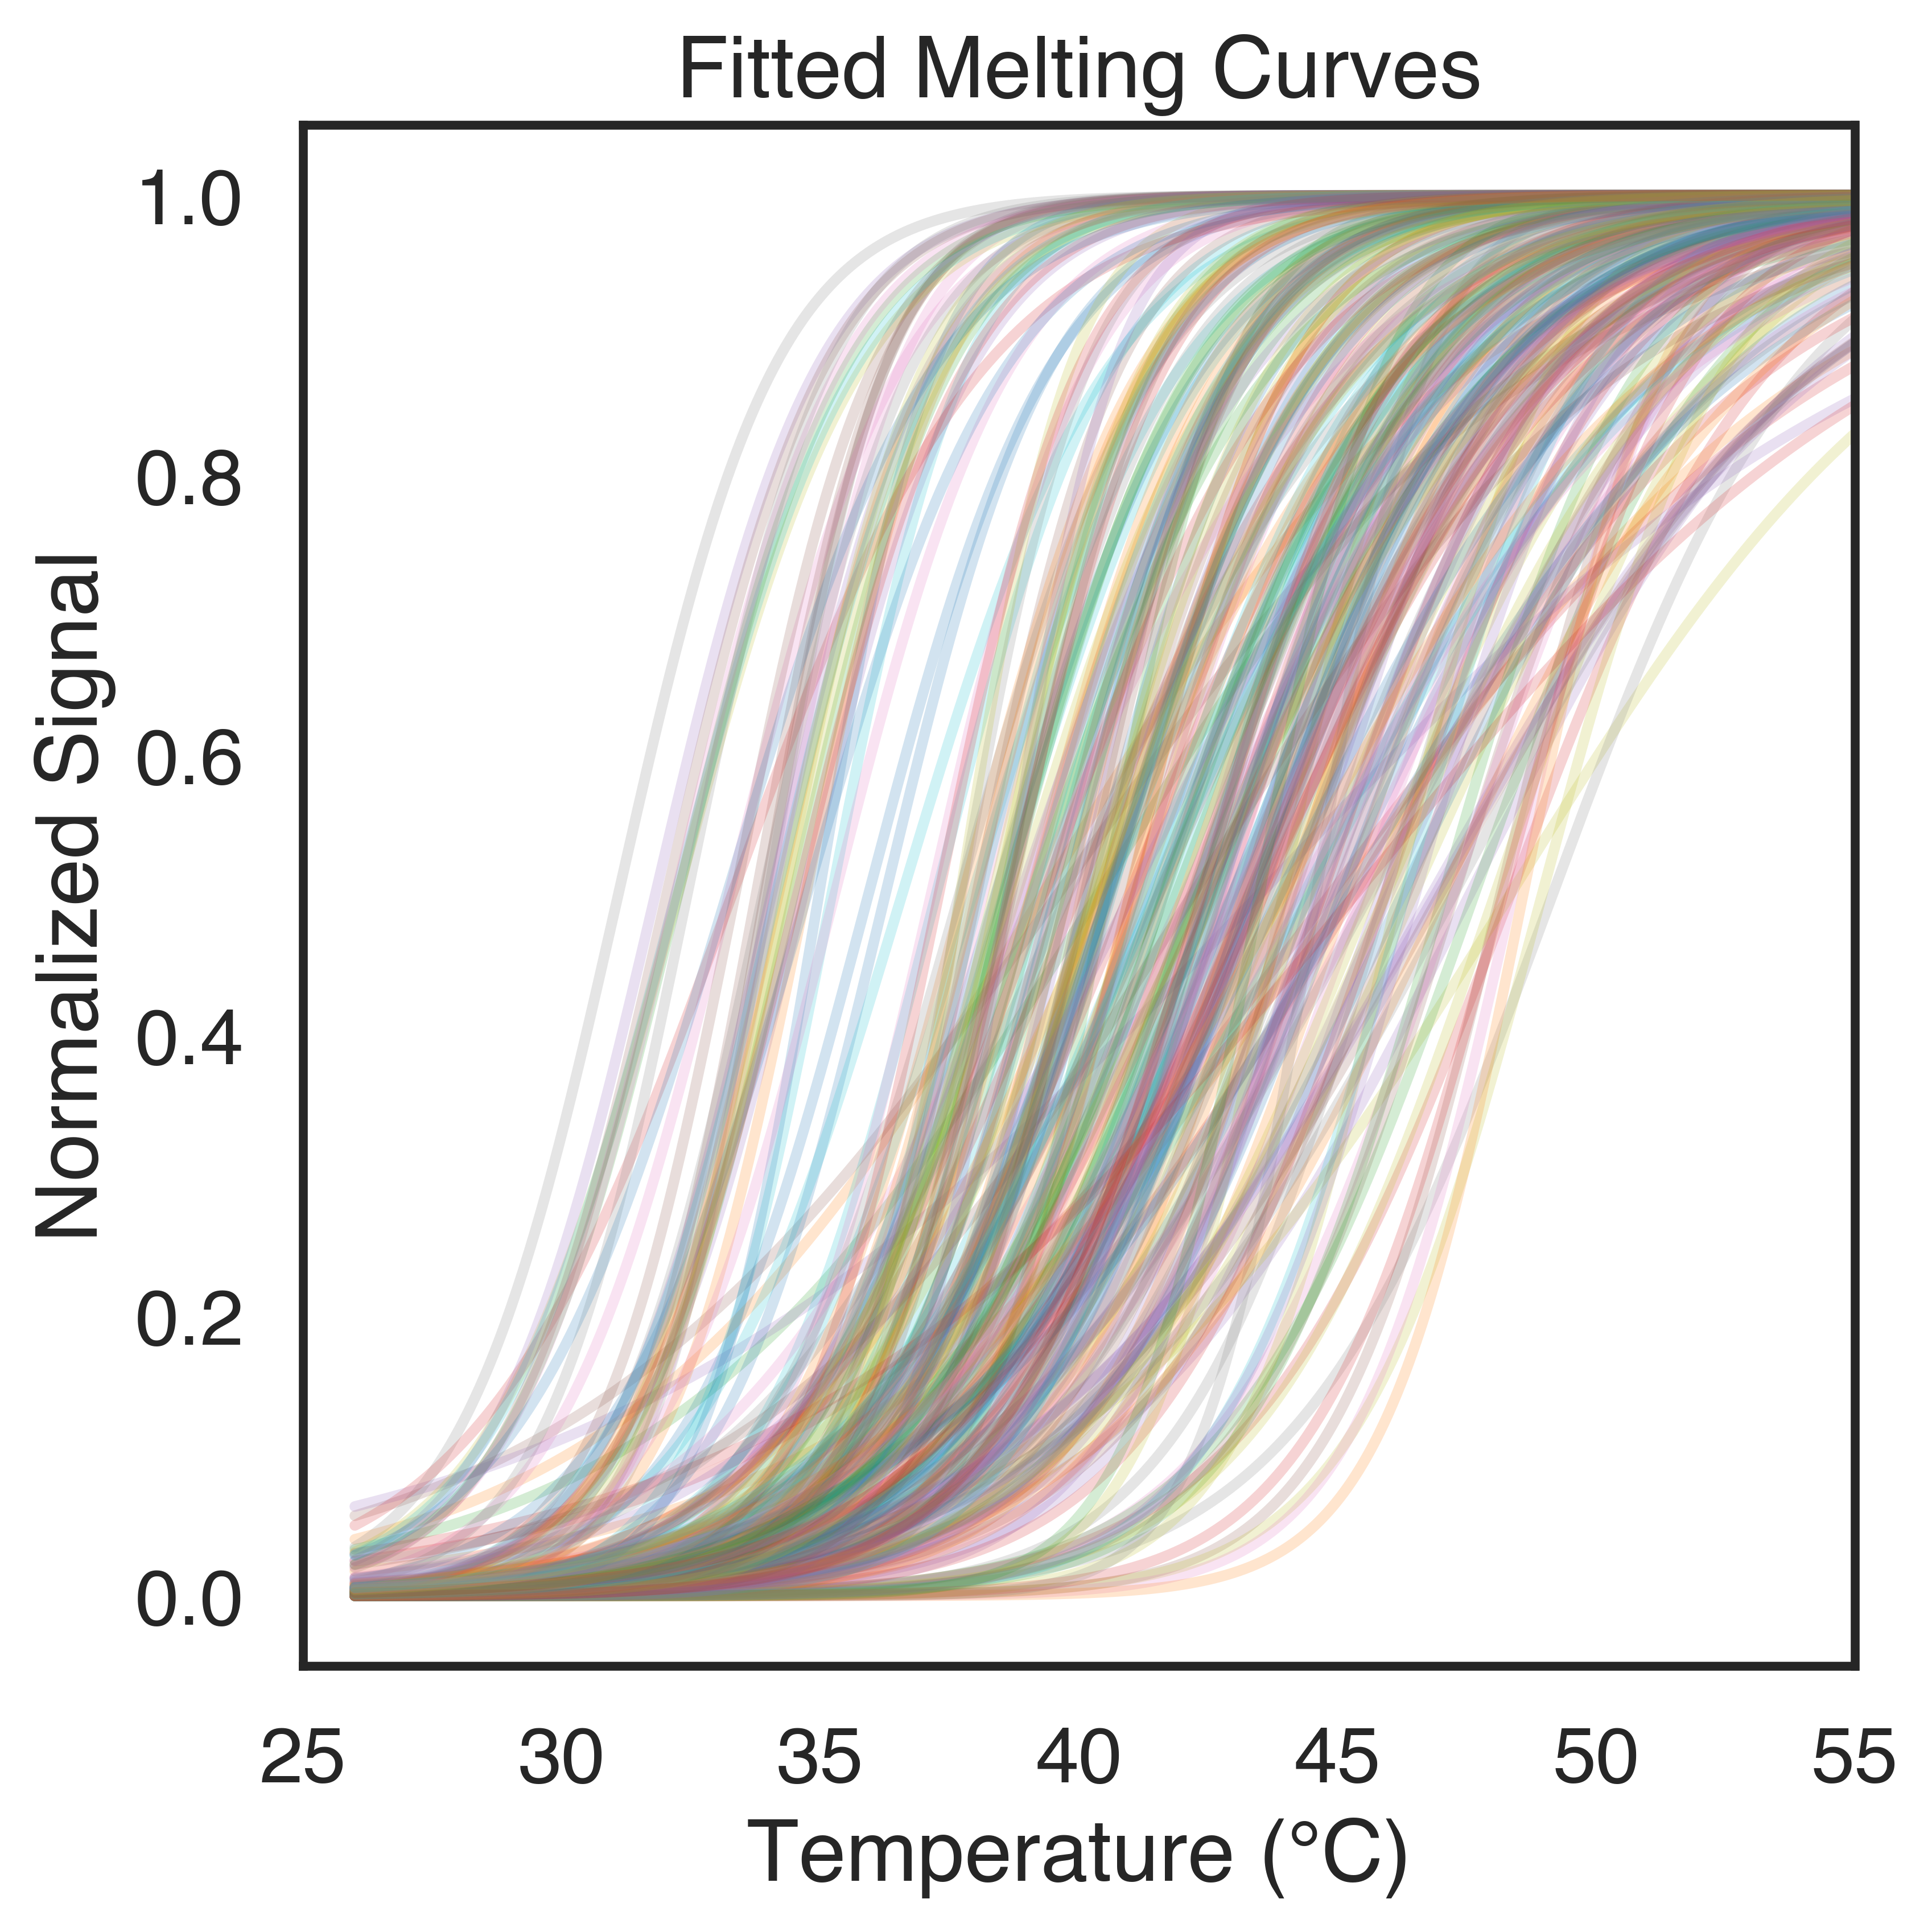

In [53]:
plt.figure(figsize=(6,6))

#df_sorted = df1.sort_values("Tm")
#df_sorted=df_sorted.iloc[np.linspace(35,1030,100)]
#df_top100 = df_sorted.tail(100)
#df_top100 = df_sorted.tail(100).iloc[::-1]

x_fit = np.linspace(
    26,
    55,
    500
)
x=0
for _, row in df_median.iterrows():
    
    A1 = row["A1"]
    A2 = row["A2"]
    Tm = row["Tm"]
    dx = row["dx"]
    if(dx < 1):
        continue
    if(Tm < 30):
        continue
    if(Tm > 50):
        continue
    if(A1 >1):
        continue
    y_curve = boltzmann(x_fit, A1, A2, Tm, dx)
    plt.ylim(0,1)
    plt.xlim(25,55)
    #y_fit=1-y_curve
    fU = (y_curve - A1) / (A2 - A1)
    plt.plot(x_fit, fU, alpha=0.2)
    x=x+1
plt.xlabel("Temperature (°C)")
plt.ylabel("Normalized Signal")
plt.title("Fitted Melting Curves")
plt.ylim(-0.05,1.05)
plt.tight_layout()
#plt.show()
plt.savefig('Figure1_Platform_AFM/Melting Curves.svg')

In [55]:
dfFilter.to_csv('Filtered_DF_std.csv')        # H/S-valid + reproducible (dH/dS analysis set)
df_HS = df1.copy()                             # interfaces with valid dH & dS (reproducible)
df_HS.to_csv('Filtered_DF_HS.csv')
df_Tm.to_csv('Filtered_DF_Tm.csv')             # valid-Tm set (Tm std <= 2.5 C)
print(f"dH/dS dataset: {df_HS['Code'].nunique()} interfaces, {len(df_HS)} curves")
print(f"Tm    dataset: {df_Tm['Code'].nunique()} interfaces, {len(df_Tm)} curves")
df_Tm_high.to_csv('Filtered_DF_Tm_high.csv')   # high-reliability subset only
print(f"Tm high-reliability: {df_Tm_high['Code'].nunique()} interfaces, {len(df_Tm_high)} curves")

dH/dS dataset: 240 interfaces, 720 curves
Tm    dataset: 235 interfaces, 716 curves
Tm high-reliability: 208 interfaces, 632 curves
